# Breast Cancer Screening with Machine Learning
**YBI Foundation - Data Science & Machine Learning Internship (45 days, July-August 2026)**
Piyush Vashishtha · B.Tech Bioinformatics, Amity University Rajasthan

> Educational project. The model is **not** a diagnostic tool.

**Question:** using the 30 cell-nucleus measurements in the Wisconsin Diagnostic Breast Cancer (WDBC) data, can we flag malignant samples reliably - and, because this is screening, without missing malignant cases?

**Plan**
1. Look at the data and check its quality
2. Test, feature by feature, how strongly benign and malignant samples differ
3. Compare four classifiers from the internship (Logistic Regression, KNN, Decision Tree, Random Forest) with 5-fold cross-validation and grid search
4. Pick a model using CV only, then check it once on the held-out test set
5. Move the decision threshold so sensitivity comes first
6. Explain the model (permutation importance, calibration)
7. Unsupervised check with K-means + PCA

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import clustering, eda, plots, train
from src.data import load_data, split

pd.set_option('display.precision', 3)
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)

## 1. Data understanding

In [2]:
X, y = load_data()
print(f'{X.shape[0]} samples, {X.shape[1]} features, missing values: {int(X.isna().sum().sum())}')
print(y.value_counts().rename({0: 'benign', 1: 'malignant'}))
X.head()

569 samples, 30 features, missing values: 0
malignant
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


Each nucleus property (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) is given three times: its **mean**, its **standard error** and its **worst** (mean of the three largest) value.

In [3]:
X.describe().T[['mean', 'std', 'min', 'max']].head(10)

,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


### Data quality audit

In [4]:
audit = eda.audit(X, y)
{k: v for k, v in audit.items() if k not in ('outliers_per_feature', 'skewness')}

{'rows': 569,
 'features': 30,
 'missing_values': 0,
 'duplicate_rows': 0,
 'all_numeric': True,
 'malignant_share': 0.3726,
 'rows_with_any_iqr_outlier': 171,
 'features_skew_above_1': 22}

In [5]:
quality = pd.DataFrame({'IQR outliers': audit['outliers_per_feature'], 'skewness': audit['skewness']})
quality.sort_values('IQR outliers', ascending=False).head(8)

,IQR outliers,skewness
area error,65,5.447
radius error,38,3.089
perimeter error,38,3.444
worst area,35,1.859
smoothness error,30,2.314
fractal dimension error,28,3.924
compactness error,28,1.902
symmetry error,27,2.195


No missing values and no duplicates. 171 rows have at least one value outside 1.5 x IQR, mostly in the standard-error features. These are real measurements of large or irregular nuclei, not entry errors, so they are kept. 22 of the 30 features are right-skewed (skewness > 1).

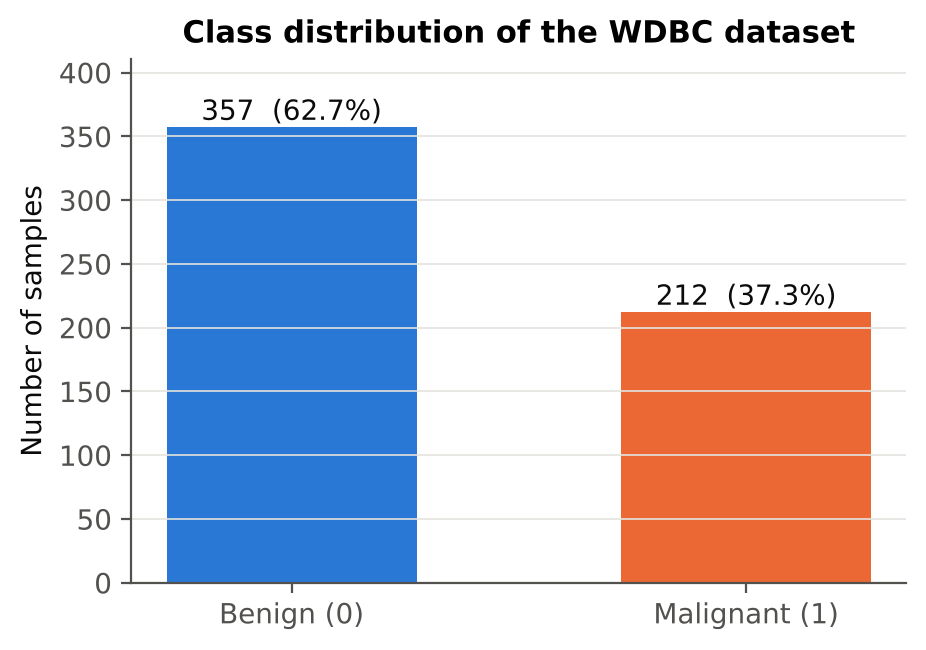

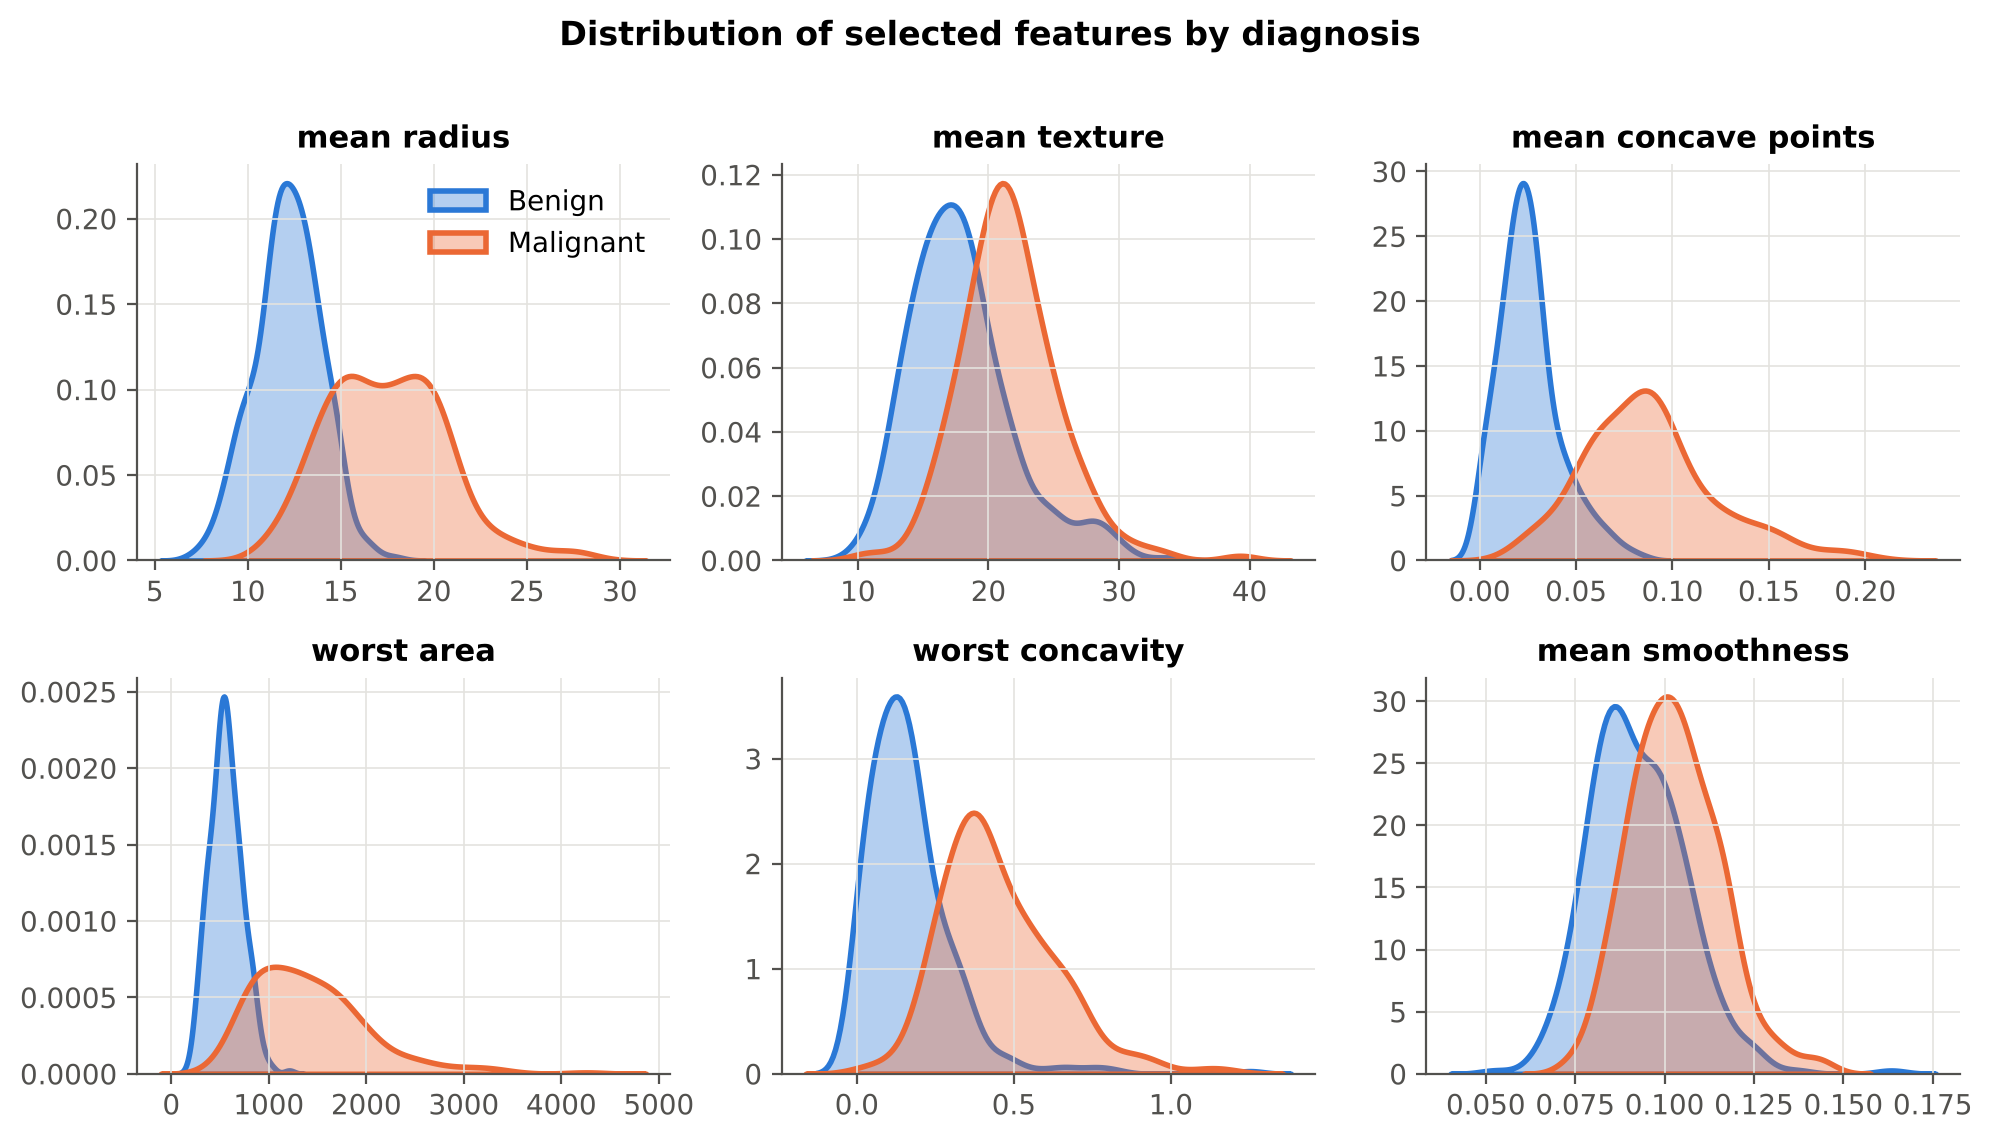

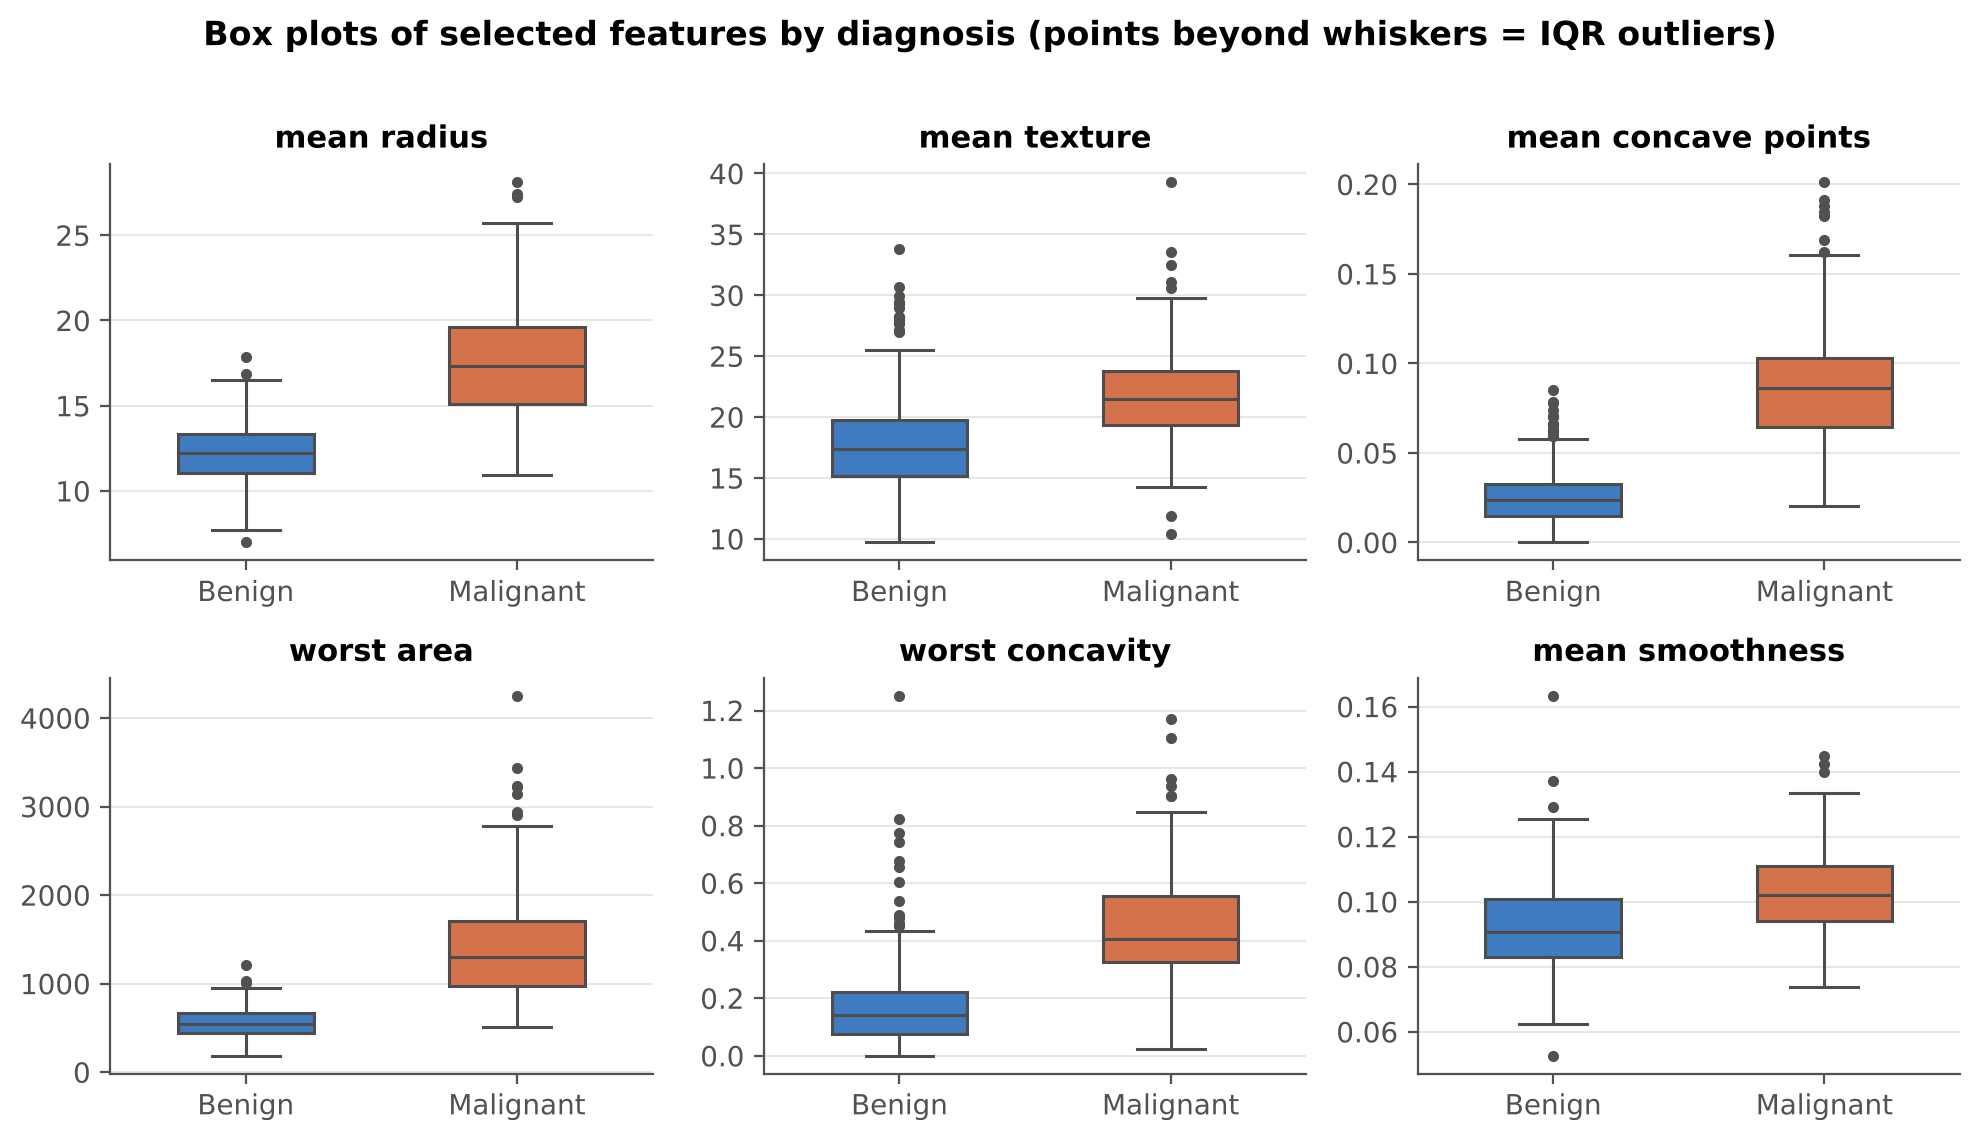

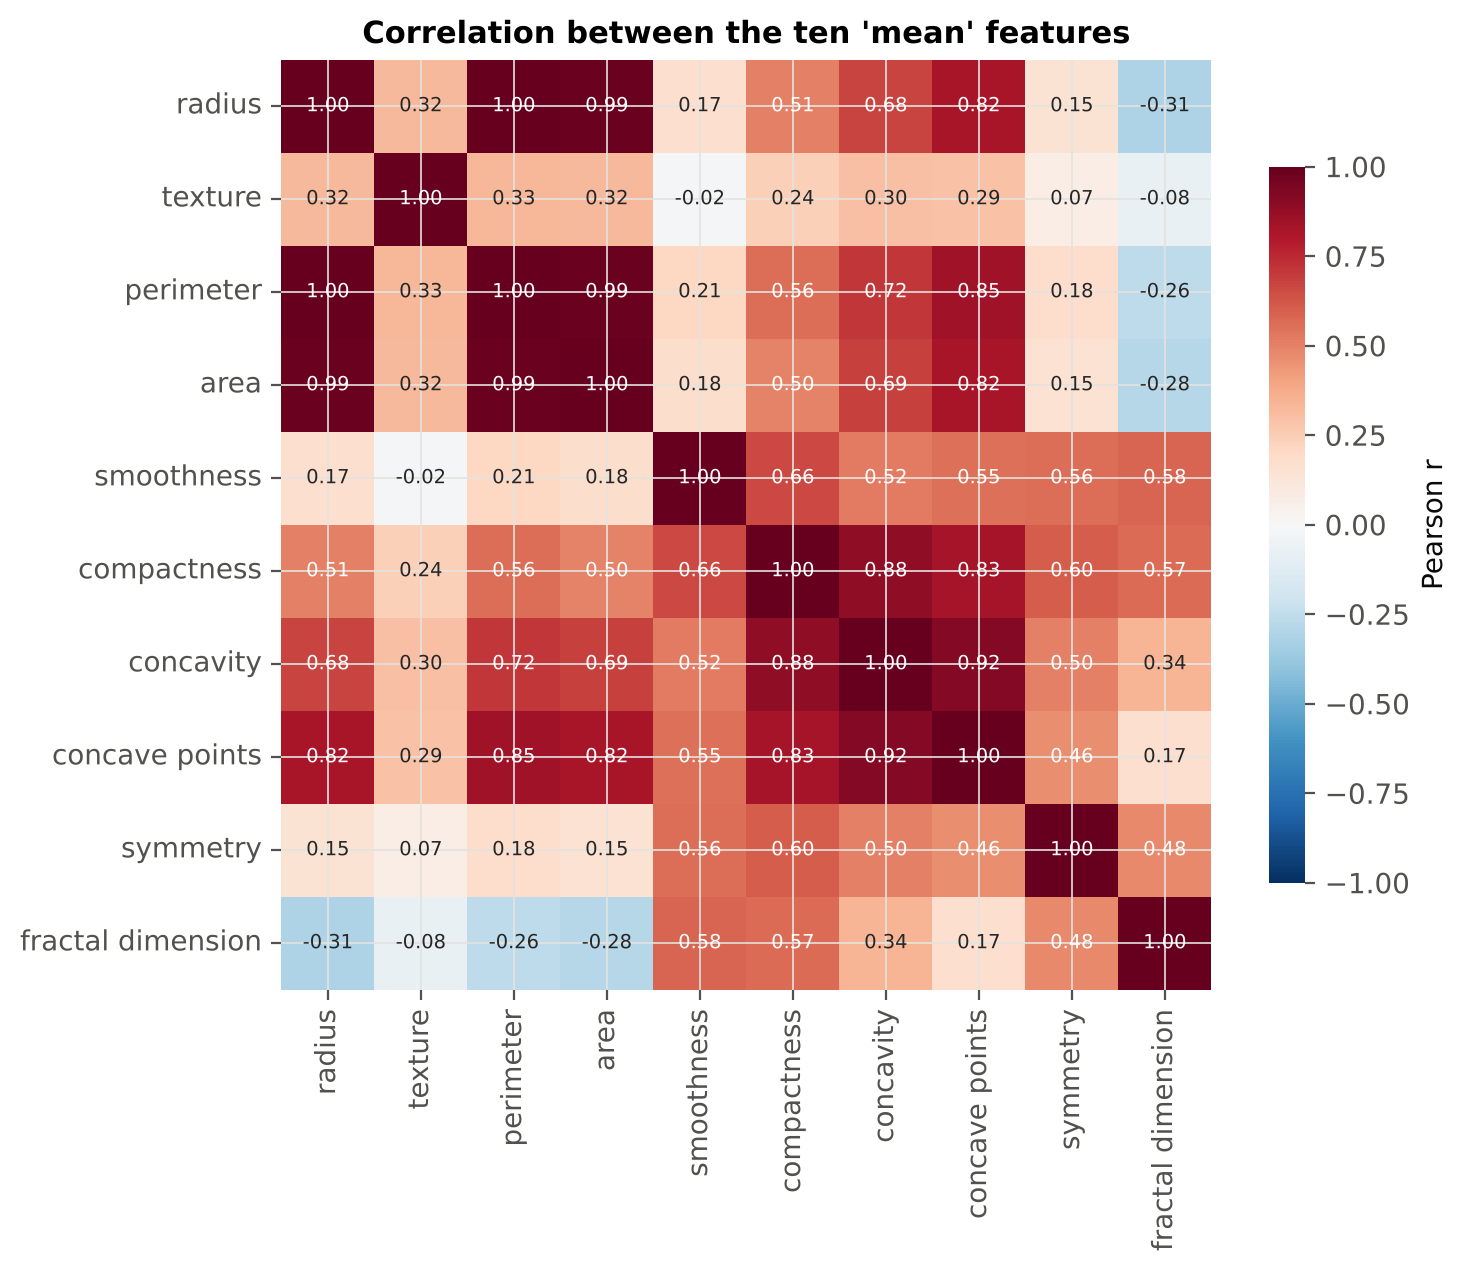

In [6]:
plots.class_balance(y, FIG)
plots.feature_distributions(X, y, FIG)
plots.boxplots(X, y, FIG)
plots.correlation_heatmap(X, FIG)
for name in ['class_balance', 'feature_distributions', 'boxplots', 'correlation_heatmap']:
    png = next(FIG.glob(f'fig0*_{name}.png'))
    display(Image(str(png), width=650))

Observations
- 63% benign / 37% malignant - imbalanced but not extreme, so I use **stratified** splits and `class_weight='balanced'` where the model supports it.
- Size features (radius, perimeter, area) are almost perfectly correlated (r > 0.98). That hurts the interpretability of linear coefficients, so later I use permutation importance instead.
- Concave points and worst area separate the classes very clearly.

## 2. Statistical testing
Because most features are skewed, I use the **Mann-Whitney U test** (non-parametric) rather than a t-test to compare benign and malignant samples, with a Bonferroni correction for 30 tests. The effect size is the rank-biserial correlation: 0 means no difference, 1 means every malignant value is larger than every benign value.

In [7]:
tests = eda.univariate_tests(X, y)
print('significant after Bonferroni:', int(tests['significant'].sum()), 'of', len(tests))
tests[['feature', 'median_benign', 'median_malignant', 'p_bonferroni', 'rank_biserial']].head(8)

significant after Bonferroni: 26 of 30


,feature,median_benign,median_malignant,p_bonferroni,rank_biserial
0,worst perimeter,86.920,138.000,7.749e-79,0.951
1,worst radius,13.350,20.590,3.407e-77,0.941
2,worst area,547.400,1303.000,5.410e-77,0.940
3,worst concave points,0.074,0.182,5.592e-76,0.933
4,mean concave points,0.023,0.086,3.019e-75,0.929
5,mean perimeter,78.180,114.200,1.066e-69,0.894
6,mean area,458.400,932.000,4.619e-67,0.877
7,mean concavity,0.037,0.151,6.494e-67,0.876


In [8]:
tests[~tests['significant']][['feature', 'p_value', 'p_bonferroni', 'rank_biserial']]

,feature,p_value,p_bonferroni,rank_biserial
26,symmetry error,0.028,0.835,-0.110
27,smoothness error,0.214,1.000,-0.062
28,mean fractal dimension,0.537,1.000,-0.031
29,texture error,0.644,1.000,0.023


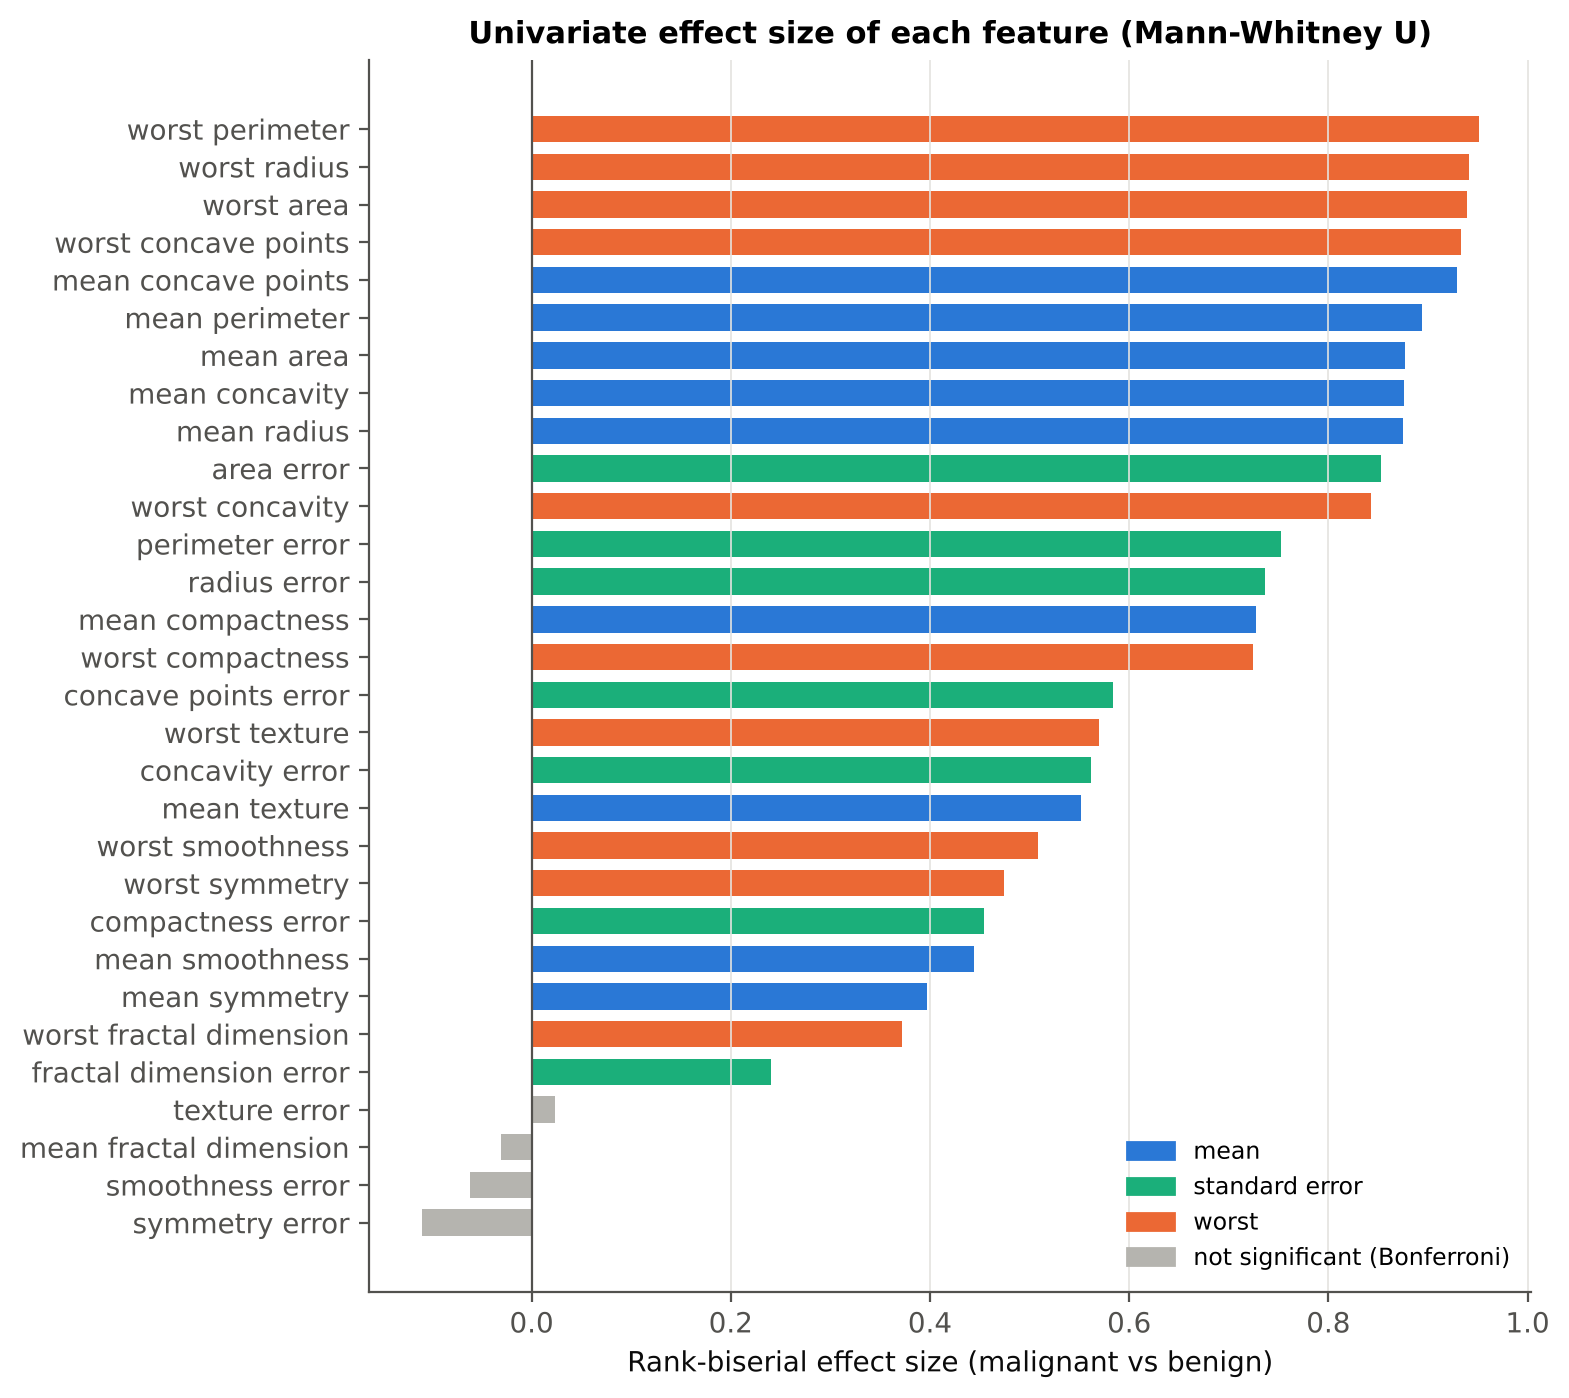

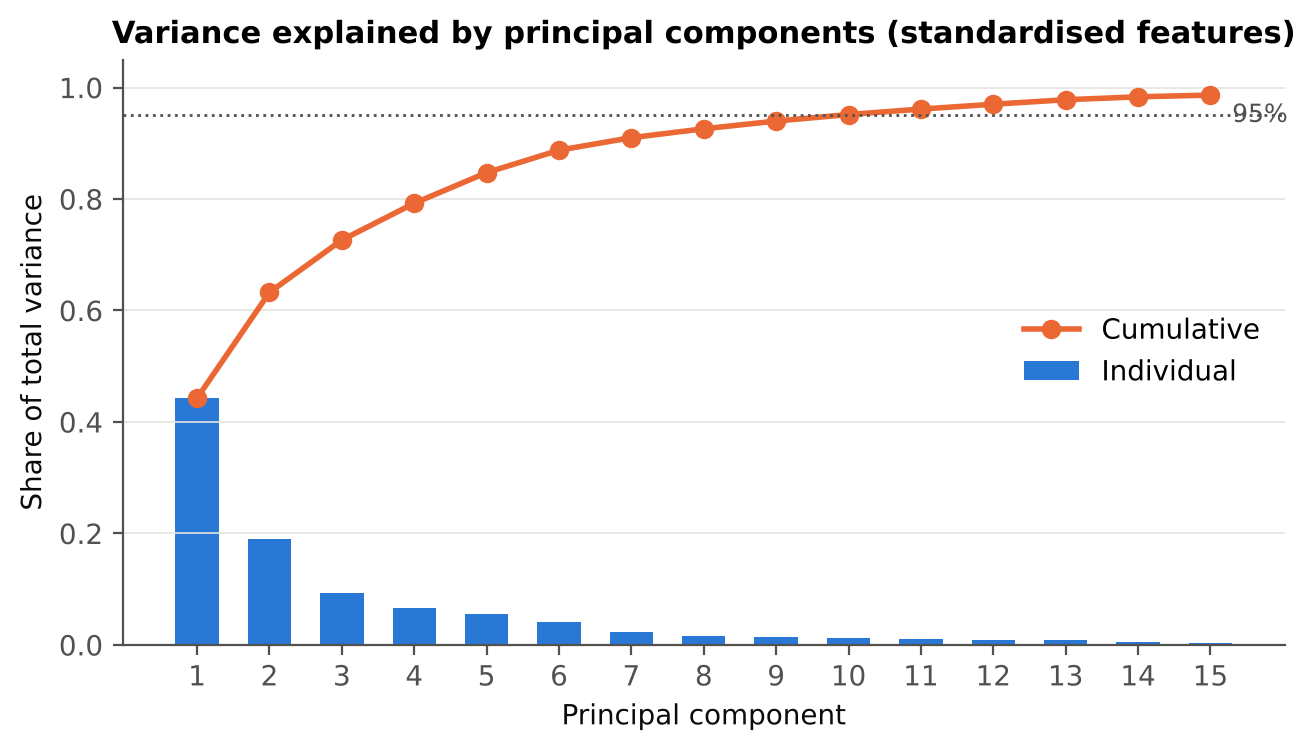

components needed for 95% of the variance: 10


In [9]:
var = eda.pca_variance(X)
plots.effect_sizes(tests, FIG)
plots.pca_variance(var, FIG)
display(Image(str(FIG / 'fig05_effect_sizes.png'), width=560))
display(Image(str(FIG / 'fig06_pca_variance.png'), width=650))
print('components needed for 95% of the variance:', int((var['cumulative'] < 0.95).sum() + 1))

26 of 30 features differ significantly. The 'worst' and size/shape features have the largest effects, while mean fractal dimension, texture error, smoothness error and symmetry error show essentially no difference. Ten principal components hold 95% of the variance, which confirms how redundant the 30 features are.

## 3. Train / test split

In [10]:
X_train, X_test, y_train, y_test = split(X, y)
print('train:', X_train.shape, 'test:', X_test.shape)
print(f'malignant share  train: {y_train.mean():.3f}   test: {y_test.mean():.3f}')

train: (426, 30) test: (143, 30)
malignant share  train: 0.373   test: 0.371


The test set (25%) is kept aside. Everything below - grid search, model choice, threshold choice - uses only the training set.

## 4. Model comparison (grid search + 5-fold CV)

In [11]:
from src.models import candidates

for name, (pipe, grid) in candidates().items():
    print(f'{name:20s}', grid)

Logistic Regression  {'clf__C': [0.01, 0.1, 1, 10]}
KNN                  {'clf__n_neighbors': [3, 5, 7, 9, 11, 15], 'clf__weights': ['uniform', 'distance']}
Decision Tree        {'clf__max_depth': [3, 4, 5, 6, None], 'clf__min_samples_leaf': [1, 3, 5]}
Random Forest        {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 6, 10], 'clf__min_samples_leaf': [1, 2]}


In [12]:
res = train.run()          # grid search, CV, test scoring, threshold, importance; saves reports/
table = res['table']
table[['model', 'best_params', 'cv_roc_auc_mean', 'cv_roc_auc_std', 'cv_recall_mean', 'cv_f1_mean']]

,model,best_params,cv_roc_auc_mean,cv_roc_auc_std,cv_recall_mean,cv_f1_mean
0,Logistic Regression,{'C': 0.1},0.992,0.007,0.950,0.959
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.989,0.006,0.937,0.937
2,KNN,"{'n_neighbors': 11, 'weights': 'distance'}",0.988,0.005,0.887,0.933
3,Decision Tree,"{'max_depth': 4, 'min_samples_leaf': 5}",0.954,0.023,0.925,0.899


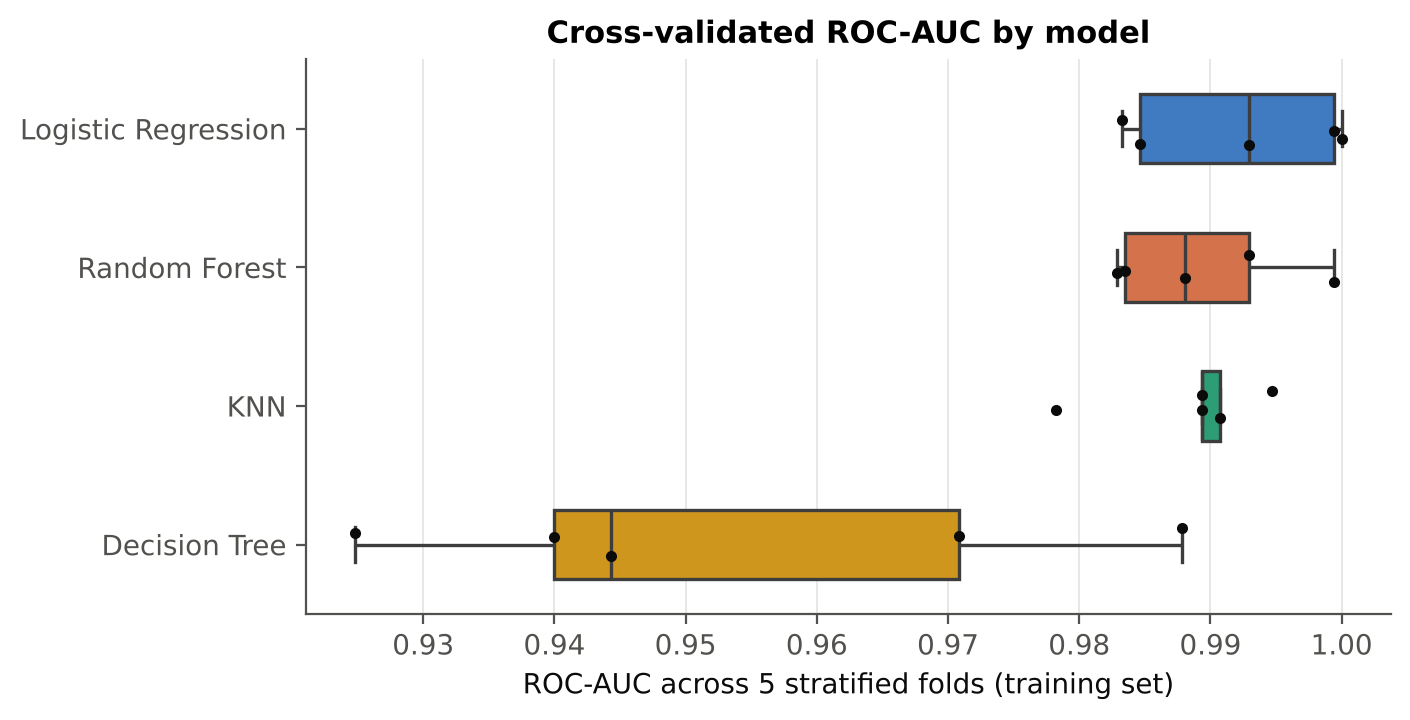

In [13]:
plots.cv_boxplot(res['folds'], list(table['model']), FIG)
display(Image(str(FIG / 'fig07_cv_roc_auc.png'), width=600))

Logistic Regression has the highest mean CV ROC-AUC, Random Forest is close behind. The single Decision Tree is clearly weaker and also the least stable across folds.

## 5. Held-out test set

In [14]:
test_cols = ['test_accuracy', 'test_precision', 'test_sensitivity',
             'test_specificity', 'test_f1', 'test_roc_auc']
table[['model'] + test_cols]

,model,test_accuracy,test_precision,test_sensitivity,test_specificity,test_f1,test_roc_auc
0,Logistic Regression,0.986,1.00,0.962,1.000,0.981,0.998
1,Random Forest,0.972,1.00,0.925,1.000,0.961,0.998
2,KNN,0.958,0.98,0.906,0.989,0.941,0.986
3,Decision Tree,0.923,0.92,0.868,0.956,0.893,0.929


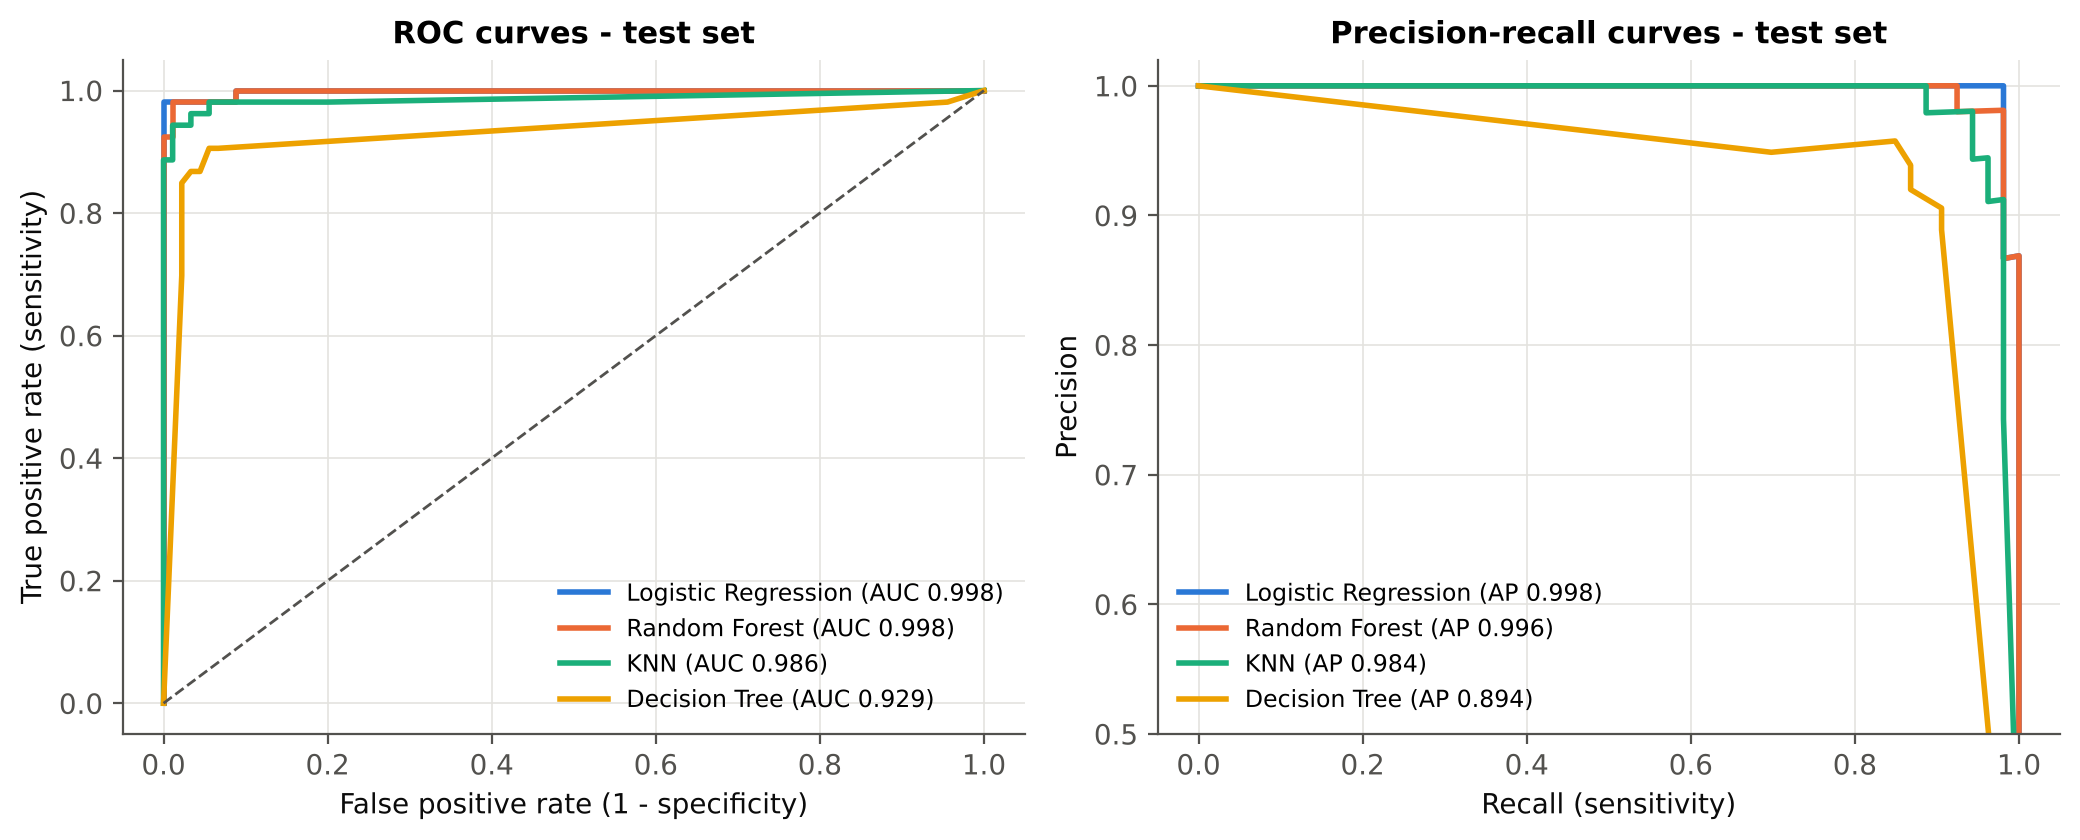

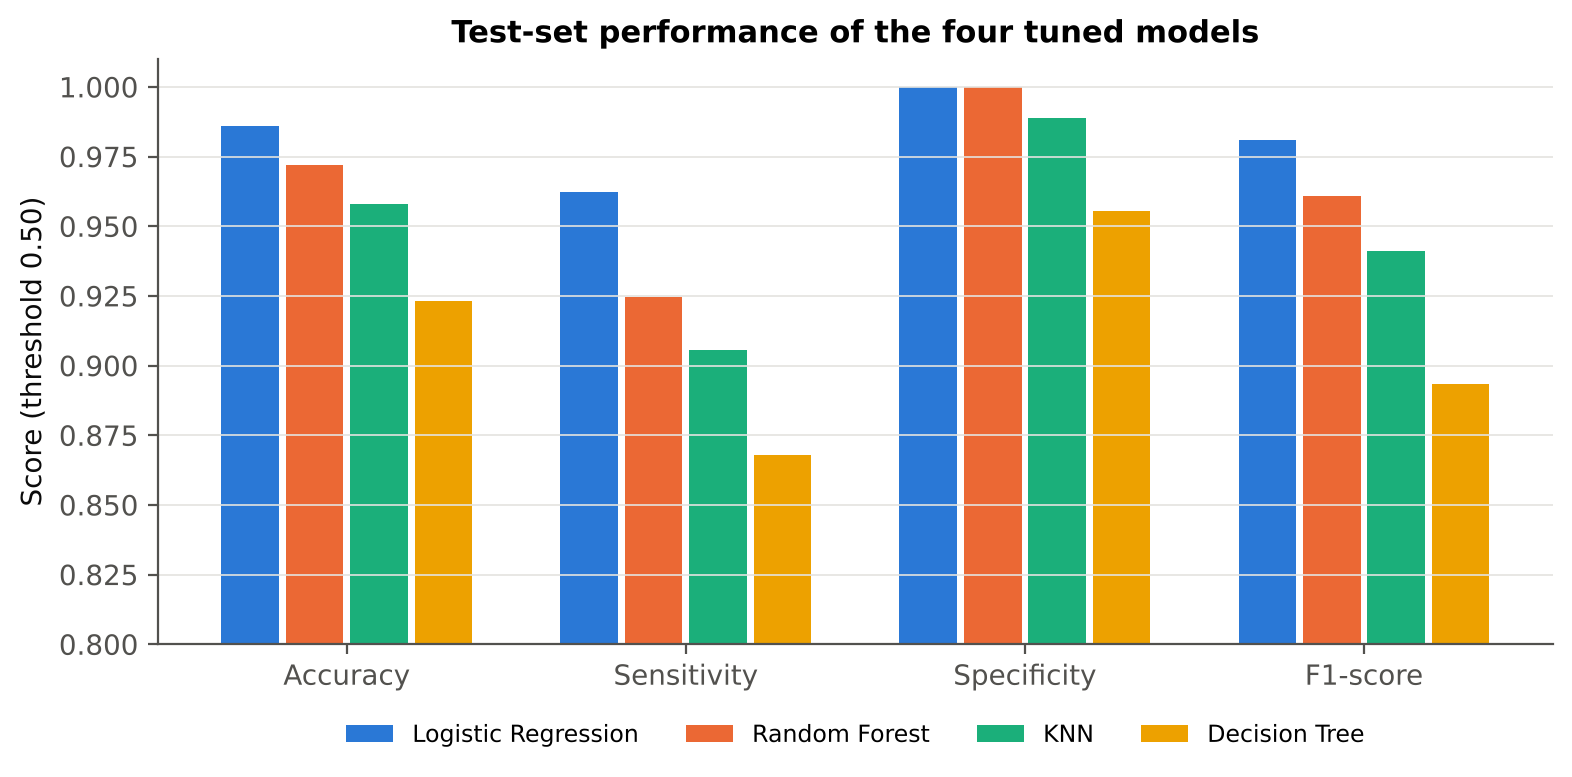

In [15]:
order = list(table['model'])
plots.roc_pr_curves(res['fitted'], X_test, y_test, order, FIG)
plots.test_metric_bars(table, order, FIG)
display(Image(str(FIG / 'fig08_roc_pr_curves.png'), width=800))
display(Image(str(FIG / 'fig09_test_metrics.png'), width=700))

The test results agree with the CV ranking, which is a good sign that the selection was not luck.

## 6. Choosing a screening threshold

In [16]:
print('selected model:', res['best_name'])
print('threshold for >= 98% out-of-fold sensitivity:', res['threshold'])
pd.DataFrame({'threshold 0.50': res['summary']['test_at_0.5'],
              f"threshold {res['threshold']}": res['summary']['test_at_tuned_threshold']}).drop(['threshold'])

selected model: Logistic Regression
threshold for >= 98% out-of-fold sensitivity: 0.19


,threshold 0.50,threshold 0.19
accuracy,0.986,0.944
precision,1.000,0.869
sensitivity,0.962,1.000
specificity,1.000,0.911
f1,0.981,0.930
roc_auc,0.998,0.998
avg_precision,0.998,0.998
brier,0.020,0.020
tn,90.000,82.000
fp,0.000,8.000


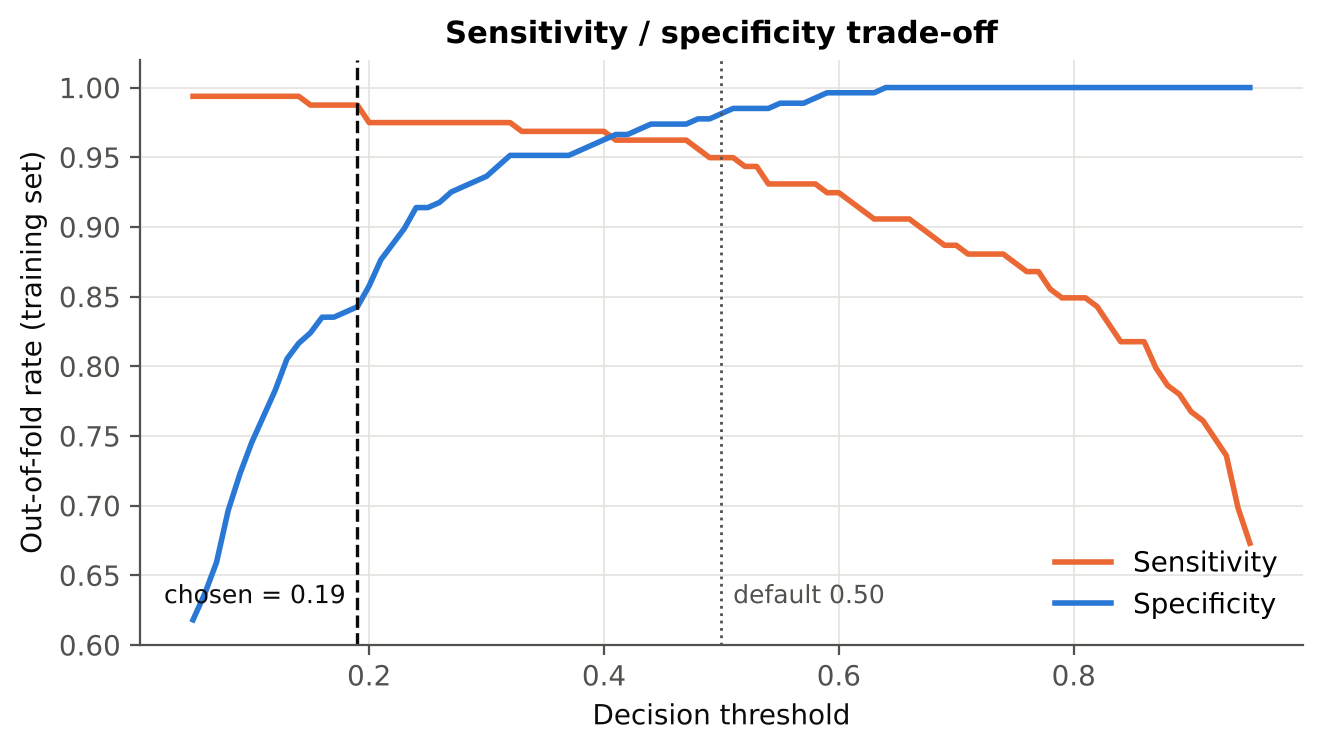

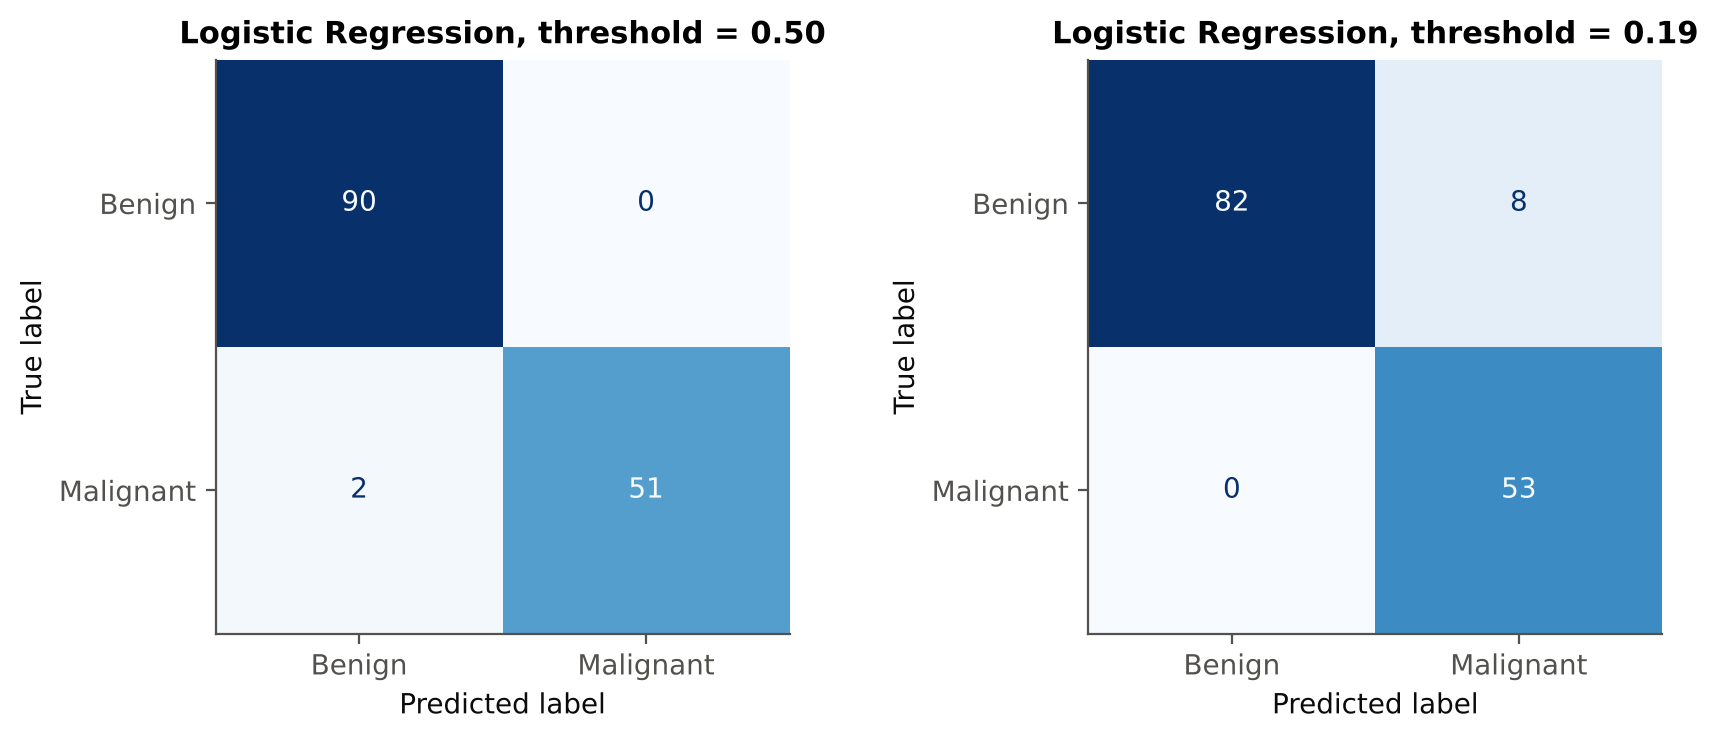

In [17]:
plots.threshold_sweep(res['sweep'], res['threshold'], FIG)
plots.confusion_pair(res['best'], X_test, y_test, res['threshold'], res['best_name'], FIG)
display(Image(str(FIG / 'fig10_threshold_sweep.png'), width=650))
display(Image(str(FIG / 'fig11_confusion_matrices.png'), width=700))

At 0.50 the model misses 2 of 53 malignant test cases. Lowering the threshold to the value picked on the training folds removes both misses, at the cost of 8 benign samples being flagged for an extra check. For a screening step that is the trade I would choose; a different clinical cost would give a different threshold.

## 7. Explaining the model

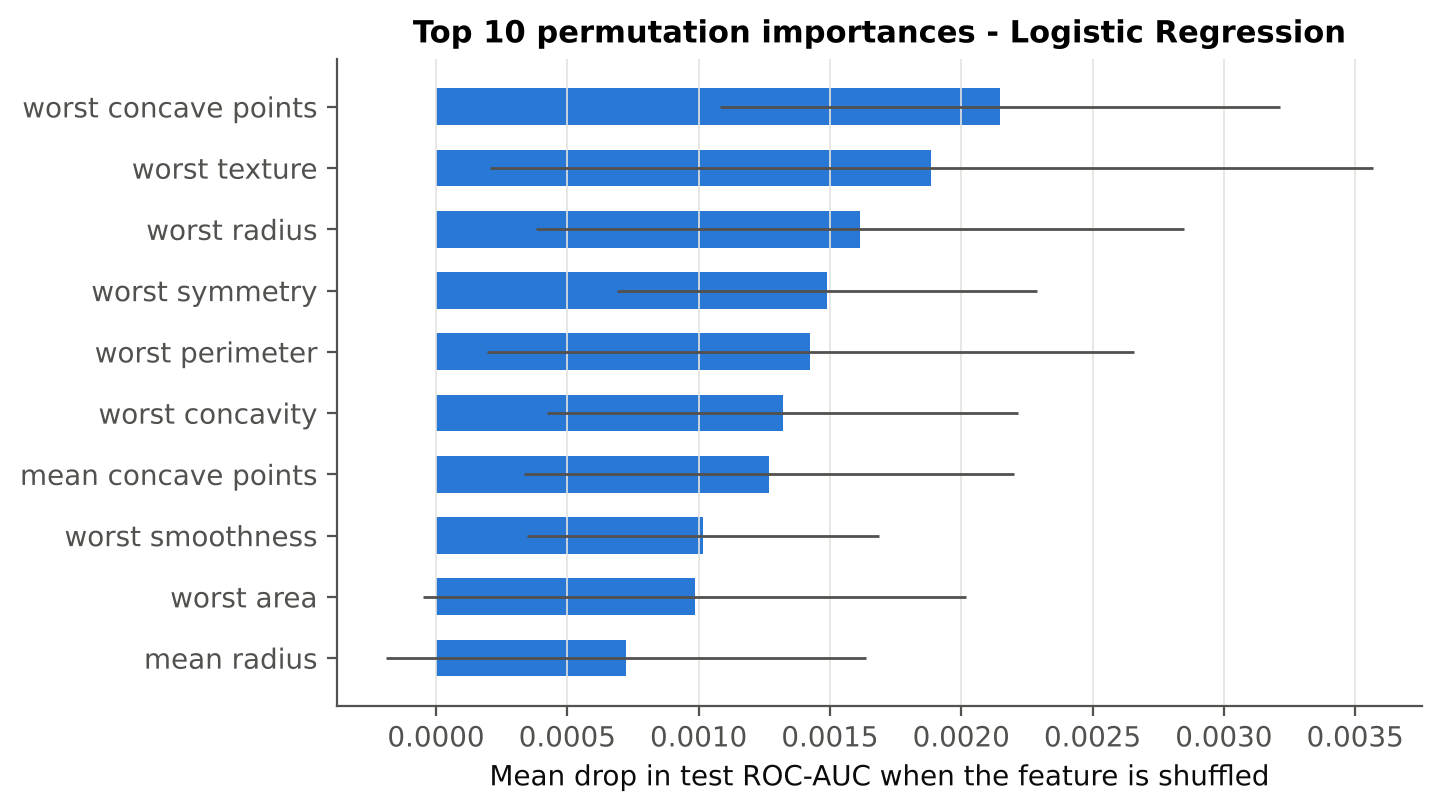

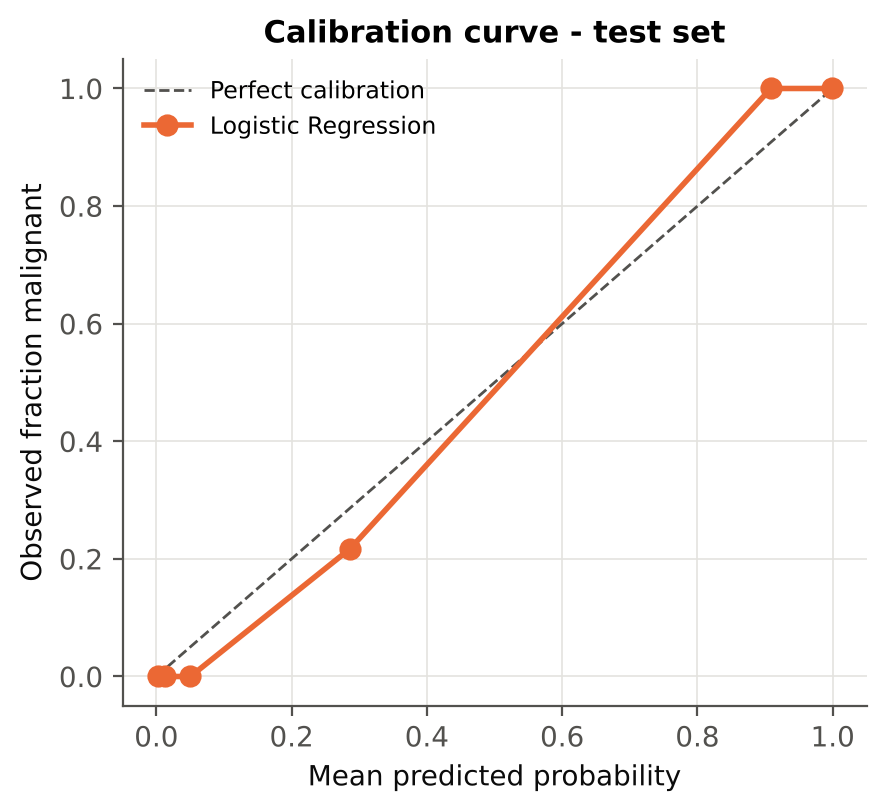

,feature,importance,std
0,worst concave points,2.149e-03,1.067e-03
1,worst texture,1.887e-03,1.680e-03
2,worst radius,1.614e-03,1.233e-03
3,worst symmetry,1.488e-03,8.008e-04
4,worst perimeter,1.426e-03,1.232e-03
5,worst concavity,1.321e-03,8.971e-04
6,mean concave points,1.268e-03,9.340e-04
7,worst smoothness,1.017e-03,6.704e-04
8,worst area,9.853e-04,1.034e-03
9,mean radius,7.233e-04,9.126e-04


In [18]:
plots.importance_bar(res['importance'], res['best_name'], FIG)
plots.calibration(res['best'], X_test, y_test, res['best_name'], FIG)
display(Image(str(FIG / 'fig12_feature_importance.png'), width=620))
display(Image(str(FIG / 'fig13_calibration.png'), width=420))
res['importance'].head(10)

Shape-irregularity features (concave points, concavity) and texture dominate, which matches what pathologists look at. The calibration curve is close to the diagonal, so the probabilities are usable as rough risk scores - although 143 test samples is too few for a firm calibration claim.

## 8. Unsupervised check - K-means

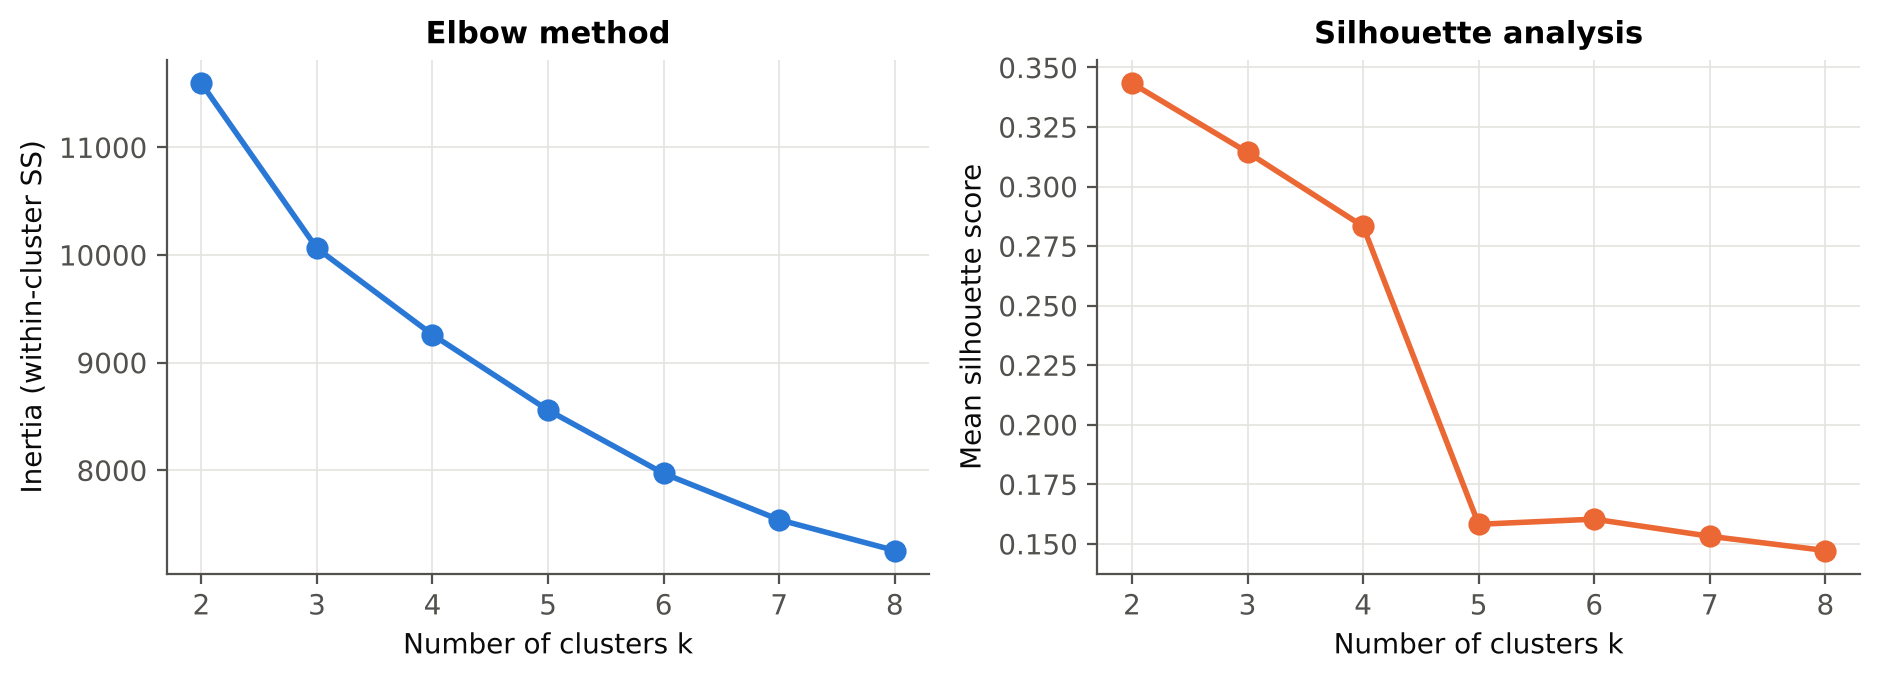

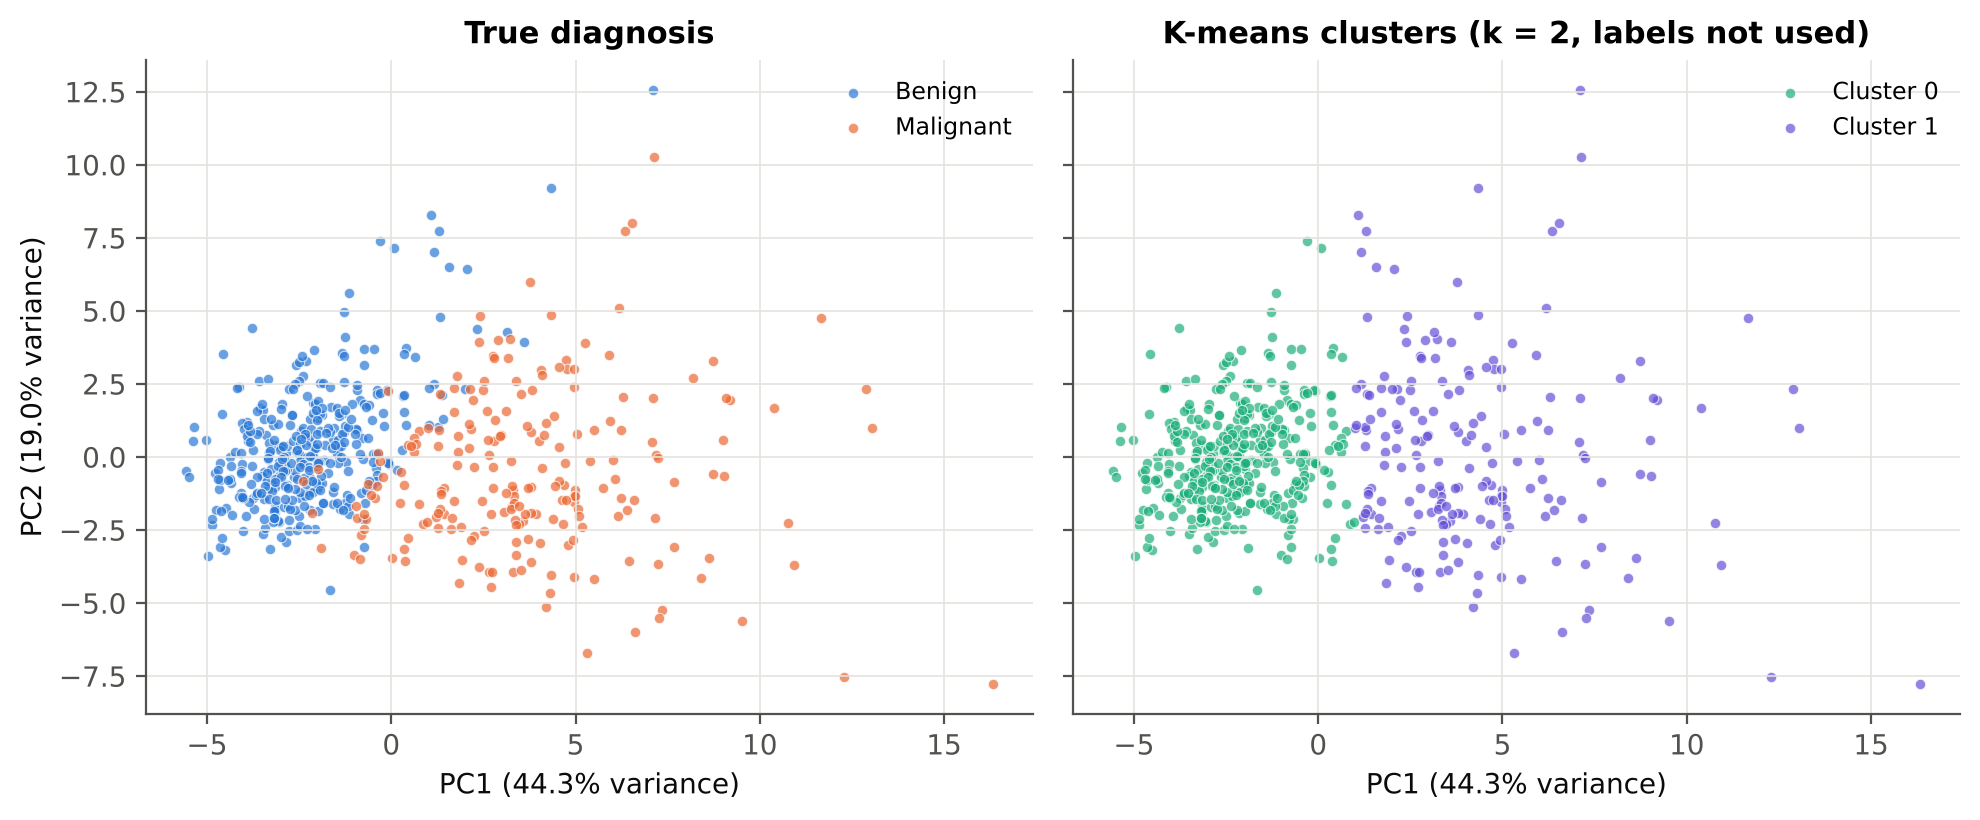

{'best_silhouette_k': 2,
 'silhouette_k2': 0.3434,
 'adjusted_rand_index_k2': 0.6536,
 'cluster_label_agreement_k2': 0.9051,
 'pca_explained_variance': [0.4427, 0.1897],
 'crosstab': {0: {0: 339, 1: 36}, 1: {0: 18, 1: 176}}}

In [19]:
km = clustering.run(X, y)
plots.kmeans_scan(km['scan'], FIG)
plots.pca_clusters(km['coords'], y, km['labels'], km['pca'], FIG)
display(Image(str(FIG / 'fig14_kmeans_k_selection.png'), width=700))
display(Image(str(FIG / 'fig15_pca_kmeans.png'), width=780))
km['summary']

Without seeing any labels, K-means with k = 2 groups about 90% of samples the same way as the diagnosis (ARI ≈ 0.65). So the benign/malignant difference is the main structure in the data - which is also why the supervised models score so high.

## 9. Conclusion and limitations
- The data are clean (no missing values or duplicates); 26 of 30 features differ significantly between the classes.
- Best model by CV: **Logistic Regression** (scaled, class-balanced). Test ROC-AUC ≈ 0.998.
- With the screening threshold, test sensitivity = 100% and specificity ≈ 91%.
- The dataset is small (569 samples), old, from one centre, and made of hand-measured image features. Real use would need external validation, calibration on local data, bias checks and clinical oversight.

Next steps I would try: SVM and gradient boosting, repeated nested CV for tighter estimates, and SHAP for per-patient explanations.

In [20]:
train.run_eda(X, y)
(ROOT / 'reports' / 'clustering.json').write_text(json.dumps(km['summary'], indent=2, default=float))
print('saved reports/ and figures/')

saved reports/ and figures/
